# Run a symbolic PDE on the CPU, a CUDA GPU or Apple silicon (MPS)

A generated equation runs through the eager PyTorch backend, so it runs wherever PyTorch
runs: on the CPU, on an NVIDIA GPU (`"cuda"`) and on Apple silicon (`"mps"`). Nothing is
compiled for a device and nothing is downloaded; the same class is built once and runs on
all of them.

Three things name the device, and they must agree:

| What | Where | Why |
| --- | --- | --- |
| `MyEquation(spatial_order, device=dev)` | the equation class | the static FD stencils live there |
| `PropTorch(..., dev=dev)` | the propagator | the wavefields and the CPML memory live there |
| `models=[vp]` | the model tensors | `vp.to(dev)`; the gradient comes back on the same device |

The wavelet and the source / receiver coordinates can stay on the CPU (NumPy arrays are
fine): the propagator moves them. This notebook detects what the machine has, runs one PDE
on every device it finds, checks that they agree and compares their speed. The outputs
below were produced on an Apple-silicon laptop, so they show `cpu` and `mps`; on a CUDA
machine the same cells add a `cuda` row.

In [1]:
import time

import numpy as np
import torch

from sweep.propagator.options import EagerOptions, Full
from sweep.propagator.torch import PropTorch
from sweep.symbolic import PDE, Eq, Field, Model, laplace


def available_devices():
    """The devices this torch can run on, fastest first: cuda, mps, cpu."""
    devs = []
    if torch.cuda.is_available():
        devs.append(("cuda", torch.cuda.get_device_name(0)))
    if torch.backends.mps.is_available():
        devs.append(("mps", "Apple silicon GPU (Metal)"))
    devs.append(("cpu", f"{torch.get_num_threads()} threads"))
    return devs


def synchronize(dev):
    """Wait for the device's queue, so a wall-clock timing means something."""
    if dev == "cuda":
        torch.cuda.synchronize()
    elif dev == "mps":
        torch.mps.synchronize()


print("torch", torch.__version__)
for name, detail in available_devices():
    print(f"  {name:5s} {detail}")

torch 2.11.0
  mps   Apple silicon GPU (Metal)
  cpu   10 threads


## The PDE

The constant-density acoustic equation with a free surface, as in the
[Acoustic · free surface](70_symbolic_acoustic.ipynb) notebook. Build it once; the class
takes its device when it is instantiated, not when it is built.

In [2]:
vp = Model("vp", unit="m/s")
p = Field("p", source=True, receiver=True)

Acoustic = PDE([Eq(p.dt2, vp**2 * laplace(p))], name="Acoustic", free_surface="zero").build(ndim=2)
Acoustic

sweep.symbolic.generated.Acoustic_2d.Acoustic

## One run, any device

A model, a shot, a forward run and the gradient with respect to `vp`. The only thing that
changes between devices is `dev`: the equation, the propagator and the model all take it.
Pass `impl="eager"` explicitly: generated classes are not in the compiled cores, and
`impl=None` ("auto") would only reach the same eager path after probing for one.

`EagerOptions(use_compile=True)` wraps the time step in `torch.compile`. The first call on a
new grid size compiles (seconds to a minute, then cached on disk); the runs after it are
several times faster, on every device. The timings below are of a second, warm call.

In [3]:
nz, nx, h, dt, nt = 200, 300, 10.0, 1e-3, 600
z, x = np.mgrid[0:nz, 0:nx]
layer = np.where(z > 80 + 12 * np.sin(2 * np.pi * x / nx), 2600.0, 1800.0)
vel = torch.tensor(layer, dtype=torch.float32)                 # on the CPU; moved per run

a = (np.pi * 12.0 * (np.arange(nt) * dt - 1.5 / 12.0)) ** 2
wavelet = torch.tensor((1 - 2 * a) * np.exp(-a), dtype=torch.float32)
src = np.array([[150, 10]])                                    # (ix, iz)
rec = np.array([[[ix, 5] for ix in range(0, nx, 3)]])


def run(dev, compile=False, repeats=2):
    """Forward + gradient on `dev`; returns the record, the gradient (both on the CPU) and the warm time."""
    solver = PropTorch(Acoustic(8, device=dev), shape=(nz, nx), dh=h, dt=dt, nt=nt, dev=dev,
                       impl="eager", memory=Full(), free_surface=True, abcn=20,
                       eager_options=EagerOptions(use_compile=compile))
    model = vel.to(dev).requires_grad_(True)
    for _ in range(repeats):                                   # the last repeat is the timed one
        model.grad = None
        synchronize(dev)
        t0 = time.perf_counter()
        record = solver(wavelet, src, rec, models=[model])
        record.square().sum().backward()
        synchronize(dev)
        elapsed = time.perf_counter() - t0
    return record.detach().cpu(), model.grad.cpu(), elapsed

## Run it everywhere

In [4]:
results = {}
for dev, _ in available_devices():
    for compile in (False, True):
        key = f"{dev} {'compiled' if compile else 'eager'}"
        results[key] = run(dev, compile=compile)
        print(f"{key:14s} {results[key][2]:7.2f} s")

mps eager         0.78 s


sweep: torch.compile is compiling the Acoustic step for a 200x300 grid (with gradients); the first call on each new grid size takes seconds to a few minutes (cached on disk for later runs). EagerOptions(use_compile=False) runs uncompiled instead.


mps compiled      0.11 s


cpu eager        14.42 s


cpu compiled      0.74 s


## The same answer on every device

Float32 arithmetic is not identical across devices (different kernels sum in a different
order), so records and gradients agree to float32 round-off, around 1e-6 relative over 600
steps, not bit for bit. Within one device, compiled and uncompiled runs differ at the same level. For bit
reproducibility between two runs on the *same* CUDA device, set
`torch.backends.cudnn.deterministic = True` (and `benchmark = False`) before the run.

In [5]:
ref_record, ref_grad, _ = results["cpu eager"]
rel = lambda a, b: ((a - b).norm() / b.norm()).item()
print(f"{'vs cpu eager':14s} {'record':>10s} {'gradient':>10s}")
for key, (record, grad, _) in results.items():
    if key != "cpu eager":
        print(f"{key:14s} {rel(record, ref_record):10.1e} {rel(grad, ref_grad):10.1e}")

vs cpu eager       record   gradient
mps eager         1.2e-06    4.4e-07
mps compiled      1.9e-06    4.1e-07
cpu compiled      1.9e-06    7.2e-07


## Speed

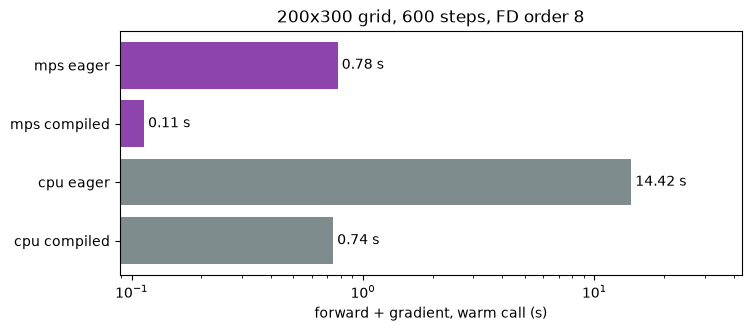

In [6]:
import matplotlib.pyplot as plt

keys = list(results)
times = [results[k][2] for k in keys]
colors = {"cpu": "#7f8c8d", "mps": "#8e44ad", "cuda": "#27ae60"}
fig, ax = plt.subplots(figsize=(7.4, 0.5 * len(keys) + 1.2), constrained_layout=True)
ax.barh(keys, times, color=[colors[k.split()[0]] for k in keys])
for i, t in enumerate(times):
    ax.text(t, i, f" {t:.2f} s", va="center")
ax.set(xscale="log", xlabel="forward + gradient, warm call (s)", title=f"{nz}x{nx} grid, {nt} steps, FD order 8")
ax.invert_yaxis()
ax.set_xlim(right=max(times) * 3)
fig.savefig("86_symbolic_devices.png", dpi=100)
plt.show()

## Notes per device

**CPU.** Always there, and the right place to write and debug a PDE: a small grid runs in
seconds and every error message is immediate. `torch.compile` pays off here most of all
(the uncompiled step launches one small kernel per operation). PyTorch uses all cores by
default; `torch.set_num_threads(n)` changes that. The shipped equations can also run on the
CPU through the compiled host core (`impl="c"`); a generated class cannot, it is eager only.

**CUDA.** `dev="cuda"` (or `"cuda:1"` for a second card). The generated class runs eager on
the GPU; it does not use the CUDA cores the wheel ships, so it is slower than a shipped
equation under `impl="c"`, but it needs no core, so it also runs where none fits. Set
`torch.backends.cudnn.allow_tf32 = False` for full-precision stencils (the shipped
notebooks do) and `cudnn.deterministic = True` when two runs must agree bit for bit. Peak
memory is that of the eager backend: `memory=Ckpt()` or `BoundarySaving()` trades time for
memory on a long run as it does for a shipped equation.

**MPS (Apple silicon).** `dev="mps"`. Metal has no float64: keep every model tensor in
float32 (`torch.tensor(..., dtype=torch.float32)`), as above; a float64 model raises at
`.to("mps")`. `torch.compile` works on MPS from torch 2.4 on and gives the same kind of
speed-up as elsewhere. Time with `torch.mps.synchronize()` around the call, as `synchronize`
does above, or the clock stops before the GPU does. An operator Metal does not implement
raises `NotImplementedError`; setting the environment variable `PYTORCH_ENABLE_MPS_FALLBACK=1`
*before* importing torch runs that one operator on the CPU instead. Small grids can be
faster on the CPU than on MPS (each kernel launch has a fixed cost); from roughly 100x100
and a few hundred steps the GPU wins.

**Moving between devices.** The record comes back on the propagator's device and the
gradient on the model's; `.cpu()` brings either to NumPy land. A solver is bound to one
device, so build one per device rather than moving it; the equation class itself is
device-free and can be instantiated on each.